# SkillBridge
## Career Recommendation and Personalized Skill-Gap Analysis for Indonesia’s Digital Job Market

**MLSC 2026 | PenaklukFCMobile**

Christian Caesar · Gerald Amadeo Passover Sutanto · Nicholas Driyadis Tjoe

## 1. Overview
Skill mismatch motivates career exploration using historical Indonesian job advertisements. The task is five-family classification and personalized skill ranking, not prediction of hiring success.

- **SDG 4 (Quality Education), target 4.4:** relevant technical and vocational skills for employment; skill gap and learning priorities support exploration.
- **SDG 8 (Decent Work and Economic Growth), target 8.5:** productive employment and decent work for all; career recommendations support exploration of occupational requirements.

Actual SDG indicators and user outcomes have not been measured. See the project README for the research questions, full data sources, algorithm rationale and limitations.

This notebook uses the same pipeline and saved artifacts as Streamlit. Run all cells for a demonstration, or enable `RETRAIN` to regenerate the research artifacts.

In [1]:
from pathlib import Path
import sys, subprocess
import pandas as pd
from IPython.display import display
root = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/core.py').exists()), None)
if root is None:
    raise FileNotFoundError('Open Jupyter from the extracted SkillBridge project.')
sys.path.insert(0, str(root))
RETRAIN = False
if RETRAIN:
    for module in ('src.train', 'src.balance'):
        subprocess.run([sys.executable, '-m', module], cwd=root, check=True)
from src.core import load, recommend, gap, explain, learning_rank, overlap
b = load()
d = pd.read_csv(root/'data/processed/jobs.csv')
print('Local profiles:', len(d), '| Default:', b['best'])

Local profiles: 2838 | Default: Hybrid


## 2. EDA
Counts represent retained unique role-skill profiles, not market share.

Sources: Indonesian Kaggle job descriptions, Web Developer dataset and Glints Indonesia; external sources are audited or used only for augmentation experiments. See `docs/DATA_SOURCES.md` for source URLs and licensing.

dataset,Local profiles,Minority augmentation
career,,
Data & AI,168,596
Design,138,99
Digital Marketing,248,0
Infrastructure & Security,219,620
Software Development,2065,0


career,Data & AI,Design,Digital Marketing,Infrastructure & Security,Software Development
source,,,,,
Glints Indonesia,46,0,0,2,0
Indonesia Kaggle,91,106,206,199,1160
International role dataset,386,99,0,619,0
Web Developer,31,32,42,18,905
glints_job_data_with_company2,26,0,0,0,0
job_list_with_description,120,0,0,0,0
job_list_with_description2,64,0,0,1,0


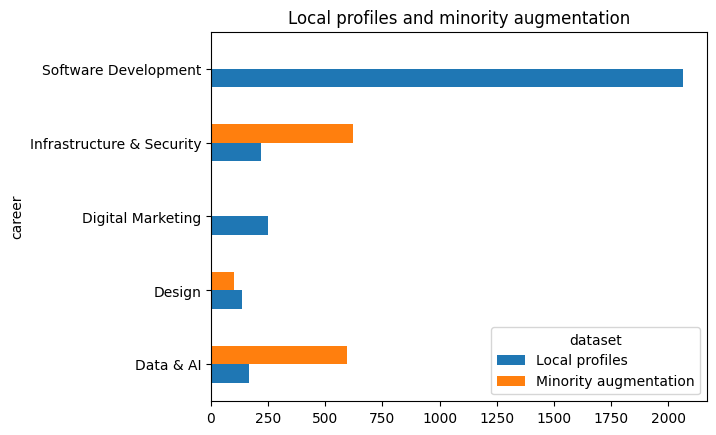

In [2]:
augmentation = pd.read_csv(root / "data/processed/balance_augmentation.csv")
comparison = pd.concat([d.assign(dataset="Local profiles"), augmentation.assign(dataset="Minority augmentation")], ignore_index=True)
display(pd.crosstab(comparison.career, comparison.dataset))
pd.crosstab(comparison.career, comparison.dataset).plot.barh(title="Local profiles and minority augmentation");
display(pd.crosstab(comparison.source, comparison.career))


## 3. Preprocessing
Title-derived labels; skills only as features. Exact duplicate role-skill profiles removed. Grouped by identical skill sets. TF-IDF fitted within training folds.

Bilingual aliases are normalized into unique skill tokens; multiword skills are encoded as deterministic UTF-8 hex tokens before TF-IDF. Records without recognized labels or skills are excluded. Title, salary, source and education are not classifier features.

In [3]:
display(pd.read_csv(root/'results/data_audit.csv'))
display(pd.crosstab(d.career,d.split))
assert not set(d[d.split=='development'].group)&set(d[d.split=='test'].group)
display(pd.read_csv(root/"results/similarity_audit.csv"))
display(pd.read_csv(root/"results/label_audit.csv"))

,source,raw,mapped,recognized,unique,usage
0,Indonesia Kaggle,5374,2763.0,2600.0,1762.0,local
1,Web Developer,2649,2222.0,1903.0,1163.0,local
2,Glints Indonesia,166,78.0,74.0,53.0,local
3,International IT,10000,3796.0,3693.0,3126.0,augmentation candidate
4,LinkedIn metadata,12217,NaN,NaN,NaN,excluded: no skills or descriptions
5,Digital gap jobs,15247,NaN,NaN,NaN,excluded: template concerns
6,Digital gap courses,3892,NaN,NaN,NaN,reference only
7,IT sentences,776,NaN,NaN,NaN,vocabulary audit only


split,development,test
career,,
Data & AI,135,33
Design,110,28
Digital Marketing,198,50
Infrastructure & Security,176,43
Software Development,1652,413


,exclude_similarity_at_or_above,retained_test,excluded_test,accuracy,macro_f1
0,1.01,567,0,0.932981,0.872323
1,1.00,567,0,0.932981,0.872323
2,0.90,564,3,0.932624,0.870713
3,0.80,512,55,0.927734,0.863597
4,0.70,416,151,0.918269,0.861427


,source,career,profiles,ambiguous_profiles
0,Glints Indonesia,Data & AI,46,5
1,Glints Indonesia,Infrastructure & Security,2,1
2,Indonesia Kaggle,Data & AI,91,7
3,Indonesia Kaggle,Design,106,22
4,Indonesia Kaggle,Digital Marketing,206,19
5,Indonesia Kaggle,Infrastructure & Security,199,21
6,Indonesia Kaggle,Software Development,1160,26
7,Web Developer,Data & AI,31,0
8,Web Developer,Design,32,6
9,Web Developer,Digital Marketing,42,6


## 4. Training & Testing
Four-fold grouped development CV selects configurations; holdout metrics are retrospective. Reproduce from project root with `python -m src.train` followed by `python -m src.balance`. The notebook reads the same fitted artifacts as Streamlit.


Naive Bayes, Logistic Regression, Linear SVM and Random Forest are evaluated against majority and weighted skill overlap baselines. Hyperparameters and hybrid mixing weights are chosen on development Macro F1. Accuracy measures top-1 correctness; Macro F1 weights classes equally; balanced accuracy averages recall; Top-3, MRR and NDCG measure ranking. Masked-skill Hit@K measures recovery of hidden skills, not learning success.

In [4]:
display(pd.read_csv(root/'results/metrics.csv').round(4))
display(pd.read_csv(root/'results/gap_evaluation.csv')[['global_hit','oracle_hit','end_to_end_hit']].mean())
display(pd.read_csv(root/'results/robustness.csv'))
display(pd.read_csv(root/'results/bootstrap_ci.csv'))
display(pd.read_csv(root/'results/gap_tuning.csv'))
display(pd.read_csv(root/'results/source_holdout.csv'))
display(pd.read_csv(root/"results/gap_v3_tuning.csv"))
display(pd.read_csv(root/"results/gap_v3_evaluation.csv")[["hit5","hit10","reciprocal_rank"]].mean())

display(pd.read_csv(root/"results/tuning.csv"))
report = pd.read_csv(root/"results/class_report.csv")
display(report[report.model.eq(b["best"])])
display(pd.read_csv(root/"results"/f"cm_{b['best']}.csv", index_col=0))

,model,split,accuracy,macro_f1,top3_hit,mrr,ndcg_at3
0,Naive Bayes,grouped CV,0.9106,0.8108,0.9947,0.9510,0.9614
1,Naive Bayes,test,0.9259,0.8504,1.0000,0.9612,0.9713
2,Logistic Regression,grouped CV,0.8617,0.7695,0.9908,0.9246,0.9402
3,Logistic Regression,test,0.8836,0.8141,0.9965,0.9368,0.9516
4,Linear SVM,grouped CV,0.8978,0.8044,0.9881,0.9422,0.9521
5,Linear SVM,test,0.9206,0.8621,0.9982,0.9563,0.9668
6,Random Forest,grouped CV,0.9014,0.7988,0.9930,0.9455,0.9566
7,Random Forest,test,0.9153,0.8336,0.9965,0.9561,0.9661
8,Majority baseline,grouped CV,0.7274,0.1684,0.8921,0.8214,0.8212
9,Majority baseline,test,0.7284,0.1686,0.8924,0.8222,0.8220


global_hit        0.261993
oracle_hit        0.446494
end_to_end_hit    0.424354
dtype: float64

,retained_fraction,accuracy,macro_f1,top3_hit,mrr,ndcg_at3
0,0.50,0.904762,0.821728,0.994709,0.948618,0.959665
1,0.75,0.925926,0.858049,0.998236,0.960758,0.970163
2,1.00,0.932981,0.872323,0.996473,0.964433,0.972116


,Unnamed: 0,accuracy,macro_f1,top3_hit,mrr,ndcg_at3
0,0.025,0.910689,0.827110,0.991218,0.951204,0.962273
1,0.975,0.953826,0.908331,1.000000,0.975285,0.980863


,policy,cv_oracle_hit_at5,n
0,frequency,0.378155,2179
1,0.25,0.414410,2179
2,0.5,0.431849,2179
3,0.75,0.445617,2179
4,1.0,0.458926,2179


,held_out_source,train_profiles,test_profiles,test_classes,accuracy,macro_f1,top3_hit,mrr,ndcg_at3
0,Glints Indonesia,2230,7,1,0.714286,0.416667,1.000000,0.857143,0.894551
1,Indonesia Kaggle,870,361,5,0.883657,0.801393,0.988920,0.933564,0.946081
2,Web Developer,1442,199,5,0.949749,0.862949,0.994975,0.972529,0.977625


,policy,cv_end_to_end_hit5,n
0,frequency,0.364387,2179
1,conditional,0.445617,2179
2,neighbor,0.463056,2179
3,blend,0.456173,2179
4,neighbor_frequency,0.445617,2179


hit5               0.446494
hit10              0.643911
reciprocal_rank    0.319855
dtype: float64

,model,parameters,accuracy,macro_f1,top3_hit,mrr,ndcg_at3,fold_macro_f1_std
0,Naive Bayes,MultinomialNB(alpha=0.1),0.910612,0.810777,0.994716,0.950961,0.961370,0.030153
1,Naive Bayes,MultinomialNB(alpha=0.5),0.907530,0.802022,0.994276,0.949728,0.960300,0.034117
2,Naive Bayes,MultinomialNB(alpha=1),0.905328,0.794213,0.993835,0.948884,0.959498,0.035920
3,Logistic Regression,"LogisticRegression(C=1, class_weight='balanced...",0.861735,0.769470,0.990753,0.924593,0.940196,0.013263
4,Logistic Regression,"LogisticRegression(C=3, class_weight='balanced...",0.856891,0.760248,0.990753,0.922127,0.938408,0.017673
5,Logistic Regression,"LogisticRegression(C=10, class_weight='balance...",0.848525,0.747681,0.990313,0.916902,0.934293,0.013242
6,Linear SVM,"LinearSVC(C=0.3, class_weight='balanced')",0.897842,0.804404,0.988111,0.942221,0.952143,0.009583
7,Linear SVM,"LinearSVC(C=1, class_weight='balanced')",0.895641,0.800263,0.985909,0.940738,0.950057,0.016605
8,Linear SVM,"LinearSVC(C=3, class_weight='balanced')",0.892558,0.794626,0.987230,0.938970,0.949349,0.016223
9,Random Forest,RandomForestClassifier(class_weight='balanced'...,0.901365,0.798829,0.992955,0.945494,0.956615,0.020019


,model,career,precision,recall,f1-score,support
35,Hybrid,Data & AI,0.837838,0.939394,0.885714,33.0
36,Hybrid,Design,0.800000,0.857143,0.827586,28.0
37,Hybrid,Digital Marketing,0.901961,0.920000,0.910891,50.0
38,Hybrid,Infrastructure & Security,0.837838,0.720930,0.775000,43.0
39,Hybrid,Software Development,0.963592,0.961259,0.962424,413.0


,Data & AI,Design,Digital Marketing,Infrastructure & Security,Software Development
Data & AI,31,0,0,0,2
Design,0,24,3,0,1
Digital Marketing,0,4,46,0,0
Infrastructure & Security,0,0,0,31,12
Software Development,6,2,2,6,397


### Class imbalance experiments
Ten scenarios use the same local split; weighting and resampling occur only on training folds. Hybrid remains the default; moderate class weighting is an optional alternative.


In [5]:
from src.core import ROOT
import pandas as pd
from IPython.display import display
display(pd.read_csv(ROOT / "results/balance_metrics.csv"))
display(pd.read_csv(ROOT / "results/balance_class_report.csv"))

,method,split,accuracy,macro_f1,top3_hit,mrr,ndcg_at3,balanced_accuracy
0,Original Hybrid,grouped CV,0.906209,0.813334,0.994276,0.947967,0.958948,0.813824
1,Original Hybrid,test,0.932981,0.872323,0.996473,0.964433,0.972116,0.879745
2,Class weighting,grouped CV,0.858212,0.764442,0.988111,0.920285,0.935730,0.848754
3,Class weighting,test,0.885362,0.824070,0.996473,0.937801,0.952463,0.914732
4,Random oversampling,grouped CV,0.865698,0.775501,0.987671,0.923551,0.937927,0.851570
5,Random oversampling,test,0.895944,0.831988,0.996473,0.942798,0.956138,0.910979
6,Random undersampling,grouped CV,0.854249,0.764175,0.985909,0.916711,0.932302,0.851449
7,Random undersampling,test,0.876543,0.806331,0.987654,0.930541,0.943414,0.893151
8,Selective augmentation,grouped CV,0.884632,0.789550,0.990753,0.934911,0.947724,0.833724
9,Selective augmentation,test,0.924162,0.863124,0.996473,0.958466,0.967707,0.903735


,method,career,precision,recall,f1-score,support
0,Original Hybrid,Data & AI,0.837838,0.939394,0.885714,33.0
1,Original Hybrid,Design,0.800000,0.857143,0.827586,28.0
2,Original Hybrid,Digital Marketing,0.901961,0.920000,0.910891,50.0
3,Original Hybrid,Infrastructure & Security,0.837838,0.720930,0.775000,43.0
4,Original Hybrid,Software Development,0.963592,0.961259,0.962424,413.0
5,Class weighting,Data & AI,0.627451,0.969697,0.761905,33.0
6,Class weighting,Design,0.702703,0.928571,0.800000,28.0
7,Class weighting,Digital Marketing,0.938776,0.920000,0.929293,50.0
8,Class weighting,Infrastructure & Security,0.584615,0.883721,0.703704,43.0
9,Class weighting,Software Development,0.986301,0.871671,0.925450,413.0


### Statistical comparison and nested evaluation
1,000 paired group-bootstrap replicates; unadjusted 95% percentile intervals. Positive differences favor the reference. Nested grouped CV uses four outer and three inner folds on development profiles. These are historical, title-derived labels, not independent human ground truth.

In [6]:
for file in ['profile_quality_summary', 'paired_model_ci', 'paired_balance_ci', 'nested_cv', 'course_audit']:
    print(file.replace('_', ' ').title())
    display(pd.read_csv(root / 'results' / f'{file}.csv').round(4))

Profile Quality Summary


,profiles,ambiguous_groups,ambiguous_profiles,at_most_two_skills
0,2838,57,127,449


Paired Model Ci


,reference,comparison,metric,difference_pp,ci_low_pp,ci_high_pp,excludes_zero,replicates
0,Hybrid,Naive Bayes,accuracy,0.7055,-0.5301,1.9435,False,1000
1,Hybrid,Naive Bayes,macro_f1,2.1944,-0.1934,4.8054,False,1000
2,Hybrid,Naive Bayes,balanced_accuracy,5.3854,1.8783,8.9804,True,1000
3,Hybrid,Logistic Regression,accuracy,4.9383,2.8315,7.2186,True,1000
4,Hybrid,Logistic Regression,macro_f1,5.8177,2.2303,9.6839,True,1000
5,Hybrid,Logistic Regression,balanced_accuracy,-2.0219,-5.7950,1.6961,False,1000
6,Hybrid,Linear SVM,accuracy,1.2346,-0.3553,2.8169,False,1000
7,Hybrid,Linear SVM,macro_f1,1.0250,-1.7088,3.6150,False,1000
8,Hybrid,Linear SVM,balanced_accuracy,-1.6421,-4.9339,1.4476,False,1000
9,Hybrid,Random Forest,accuracy,1.7637,-0.3534,3.8529,False,1000


Paired Balance Ci


,reference,comparison,metric,difference_pp,ci_low_pp,ci_high_pp,excludes_zero,replicates
0,Original Hybrid,Class weighting,accuracy,4.7619,2.6454,7.0175,True,1000
1,Original Hybrid,Class weighting,macro_f1,4.8253,1.5083,8.1331,True,1000
2,Original Hybrid,Class weighting,balanced_accuracy,-3.4987,-7.1168,-0.5211,True,1000
3,Original Hybrid,Random oversampling,accuracy,3.7037,1.7730,5.6743,True,1000
4,Original Hybrid,Random oversampling,macro_f1,4.0335,0.9421,6.9281,True,1000
5,Original Hybrid,Random oversampling,balanced_accuracy,-3.1234,-6.5473,-0.4719,True,1000
6,Original Hybrid,Random undersampling,accuracy,5.6437,3.6649,7.8014,True,1000
7,Original Hybrid,Random undersampling,macro_f1,6.5992,3.5011,9.6848,True,1000
8,Original Hybrid,Random undersampling,balanced_accuracy,-1.3406,-4.1335,0.9322,False,1000
9,Original Hybrid,Selective augmentation,accuracy,0.8818,-0.5282,2.2928,False,1000


Nested Cv


,outer_fold,selected,alpha,inner_macro_f1,test_profiles,accuracy,macro_f1,top3_hit,mrr,ndcg_at3,balanced_accuracy
0,1,NB alpha=0.1,0.5,0.8242,567,0.9153,0.8278,0.9929,0.9535,0.9625,0.8106
1,2,NB alpha=1,0.5,0.8144,567,0.9030,0.8121,0.9947,0.9460,0.9576,0.8010
2,3,NB alpha=0.1,0.5,0.8155,566,0.9117,0.8247,0.9912,0.9506,0.9595,0.8397
3,4,NB alpha=0.1,0.5,0.8129,571,0.8984,0.7985,0.9895,0.9433,0.9534,0.8062
4,pooled,fold-specific,NaN,NaN,2271,0.9071,0.8161,0.9921,0.9483,0.9582,0.8143


Course Audit


,raw_rows,unique_titles,unique_focus_patterns,unique_recognized_topic_focus_pairs,recognized_skills,masked_profiles,masked_skills_covered
0,3892,55,11,40,15,542,192


## 5. Prediction
Same model and functions as Streamlit. Coverage is weighted skill overlap, not hiring probability.

In [7]:
# Editable demonstration parameters
USER_SKILLS = ['Python', 'SQL', 'Pandas', 'Statistics', 'Power BI']
MODEL_NAME = b['best']  # e.g. 'Balancing experiment', 'Linear SVM', 'Naive Bayes'
TARGET_CAREER = None  # None selects the highest ranked career
SKILLS_TO_LEARN = ['Machine learning', 'Tableau']

known = sorted(set(USER_SKILLS) & set(b['vocabulary']))
print('Available models:', [*b['models'], 'Hybrid'])
print('Unrecognized skills:', sorted(set(USER_SKILLS) - set(known)))
r = recommend(b, known, MODEL_NAME)
if r.empty:
    print('Select at least one recognized skill.')
else:
    display(r.head(3))
    career = TARGET_CAREER or r.iloc[0].Career
    print('Target career:', career)
    g = gap(b, career, known)
    display(g[g.Have])
    from src.course_matching import match_topics
    missing = learning_rank(b, career, known)
    display(missing.head(8))
    print('Historical learning topics matched to missing skills:')
    display(match_topics(missing))
    specs = b['specializations'].get(career, {})
    if specs:
        display(pd.DataFrame([{'Specialization': k, 'Coverage': overlap({k:v}, known, [k])[0]} for k,v in specs.items()]).sort_values('Coverage', ascending=False))
    p = b['profiles'][career]
    before = overlap({career:p}, known, [career])[0]
    new = sorted(set(SKILLS_TO_LEARN) & set(p) - set(known))
    after = overlap({career:p}, known + new, [career])[0]
    display(pd.DataFrame([{'Current coverage':before, 'Simulated coverage':after, 'Gain (pp)':100*(after-before), 'Added skills':', '.join(new)}]))
    display(explain(b, known, career, MODEL_NAME))
    print('Coverage is not a hiring probability. Specializations are descriptive rankings.')

Available models: ['Naive Bayes', 'Logistic Regression', 'Linear SVM', 'Random Forest', 'Majority baseline', 'International augmentation', 'Balancing experiment', 'Hybrid']
Unrecognized skills: []


,Career,Model score,Skill coverage
0,Data & AI,0.819186,0.325885
1,Software Development,0.097874,0.080507
2,Infrastructure & Security,0.081872,0.073964


Target career: Data & AI


,Skill,Demand share,Have
0,SQL,0.481481,True
1,Python,0.451852,True
3,Statistics,0.244444,True
12,Power BI,0.118519,True


,Skill,Demand share,Learning priority score
0,Tableau,0.177778,0.267664
1,Data analysis,0.274074,0.235409
2,Machine learning,0.170370,0.196896
3,Excel,0.155556,0.159972
4,Data visualization,0.096296,0.139671
5,ETL,0.237037,0.130597
6,Hadoop,0.177778,0.119150
7,Java,0.162963,0.092988


Historical learning topics matched to missing skills:


,Learning topic,Matched missing skills,Priority score
0,Business Computing Applications,Data visualization,0.139671
1,Business Intelligence Basics,Data visualization,0.139671
2,Enterprise Applications,Data visualization,0.139671
3,Management Information Tools,Data visualization,0.139671
4,Office Productivity Tools,Data visualization,0.139671
5,Algorithm and Programming,"C++, Java",0.096779
6,Data Structures and Algorithms,"C++, Java",0.096779
7,Introduction to Software Development,"C++, Java",0.096779
8,Object-Oriented Programming,"C++, Java",0.096779
9,Programming Fundamentals,"C++, Java",0.096779


,Specialization,Coverage
2,Data science,0.358333
0,Data analytics,0.312195
1,Data engineering,0.266667


,Current coverage,Simulated coverage,Gain (pp),Added skills
0,0.325885,0.413408,8.752328,"Machine learning, Tableau"


,Skill,Score change when removed
1,Power BI,0.052675
4,Statistics,0.048782
0,Pandas,0.034198
2,Python,0.000836
3,SQL,-0.048371


Coverage is not a hiring probability. Specializations are descriptive rankings.


## 6. Interpretasi hasil
Hybrid dipilih berdasarkan Macro F1 development CV. Moderate class weighting meningkatkan recall minoritas dengan trade-off Macro F1. Evaluasi holdout bersifat retrospektif dan label berasal dari judul lowongan; skor menunjukkan kesesuaian kategori lowongan, bukan hasil rekrutmen.


Paired group bootstrap tidak menetapkan superioritas Hybrid atas Naive Bayes, Linear SVM, dan Random Forest. Nested grouped CV mengukur prosedur tuning terbatas pada data development. Label berasal dari judul; review manusia merupakan prosedur terpisah, belum menghasilkan skor. Topik belajar berasal dari metadata kurikulum historis, bukan katalog kursus aktif.